# MachineGuard — Feature Analysis

This notebook analyzes the engineered time-domain vibration features
extracted from NASA IMS Set 1, Bearing 4 X-axis.

The goal is to understand how each feature evolves over the run-to-failure
experiment before using the features for machine learning.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
file_path = Path("../data/processed/ims_set1_bearing4_x_features.csv")

features_df = pd.read_csv(
    file_path,
    parse_dates=["timestamp"],
)

In [3]:
features_df.head()

,rms,std,peak,crest_factor,kurtosis,dominant_frequency,spectral_energy,timestamp
0,0.109020,0.060085,0.413,3.788279,3.790250,986.328125,757118.612018,2003-10-22 12:06:24
1,0.108900,0.059420,0.420,3.856767,4.234703,986.328125,740448.654400,2003-10-22 12:09:13
2,0.110319,0.059968,0.396,3.589583,3.924708,986.328125,754376.681760,2003-10-22 12:14:13
3,0.111037,0.059915,0.393,3.539356,3.652667,986.328125,752875.194856,2003-10-22 12:19:13
4,0.110190,0.059255,0.376,3.412278,3.635576,986.328125,736347.011716,2003-10-22 12:24:13


In [4]:
features_df.dtypes

rms                          float64
std                          float64
peak                         float64
crest_factor                 float64
kurtosis                     float64
dominant_frequency           float64
spectral_energy              float64
timestamp             datetime64[us]
dtype: object

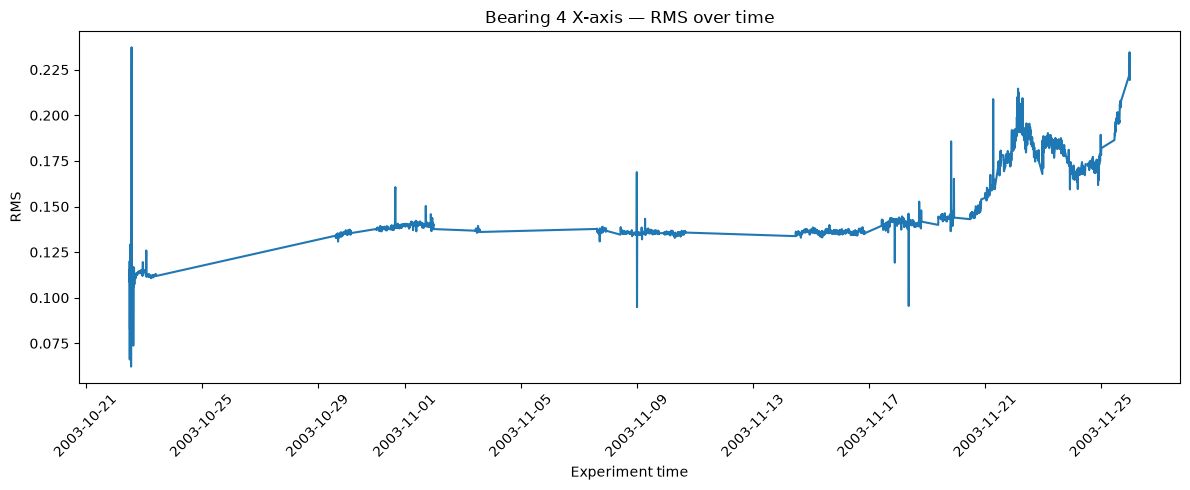

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["rms"],
)

plt.xlabel("Experiment time")
plt.ylabel("RMS")
plt.title("Bearing 4 X-axis — RMS over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

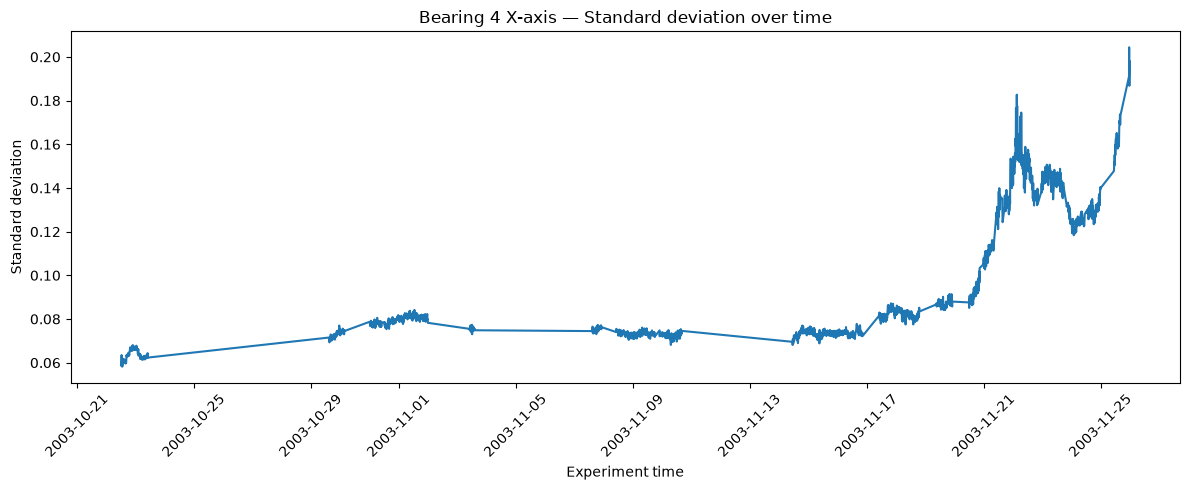

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["std"],
)

plt.xlabel("Experiment time")
plt.ylabel("Standard deviation")
plt.title("Bearing 4 X-axis — Standard deviation over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

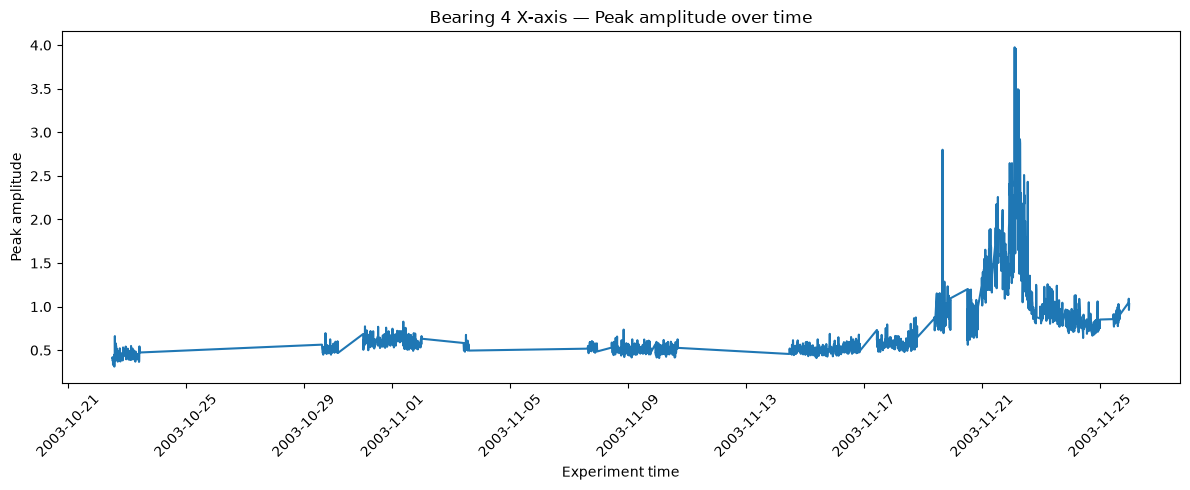

In [7]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["peak"],
)

plt.xlabel("Experiment time")
plt.ylabel("Peak amplitude")
plt.title("Bearing 4 X-axis — Peak amplitude over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

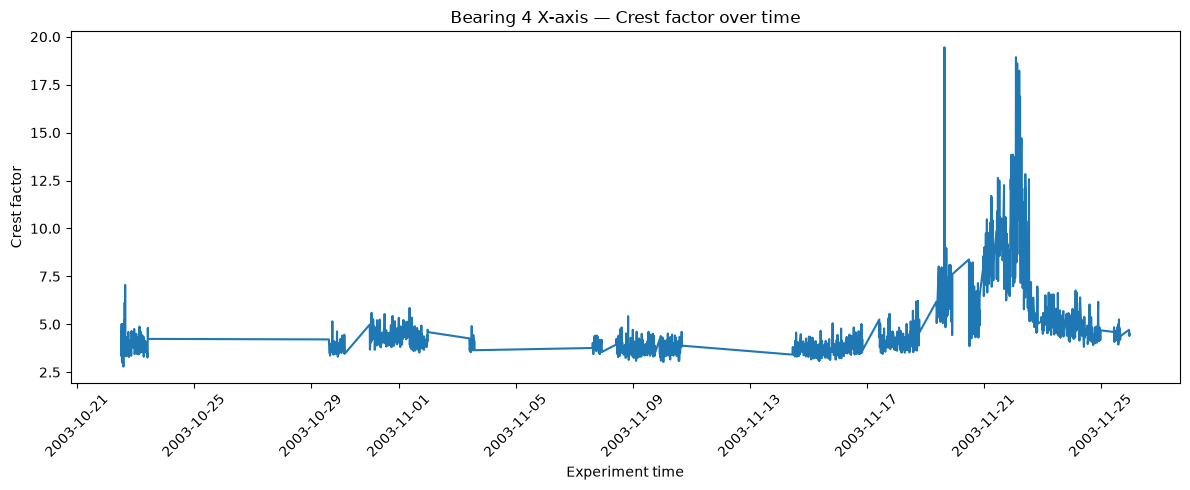

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["crest_factor"],
)

plt.xlabel("Experiment time")
plt.ylabel("Crest factor")
plt.title("Bearing 4 X-axis — Crest factor over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

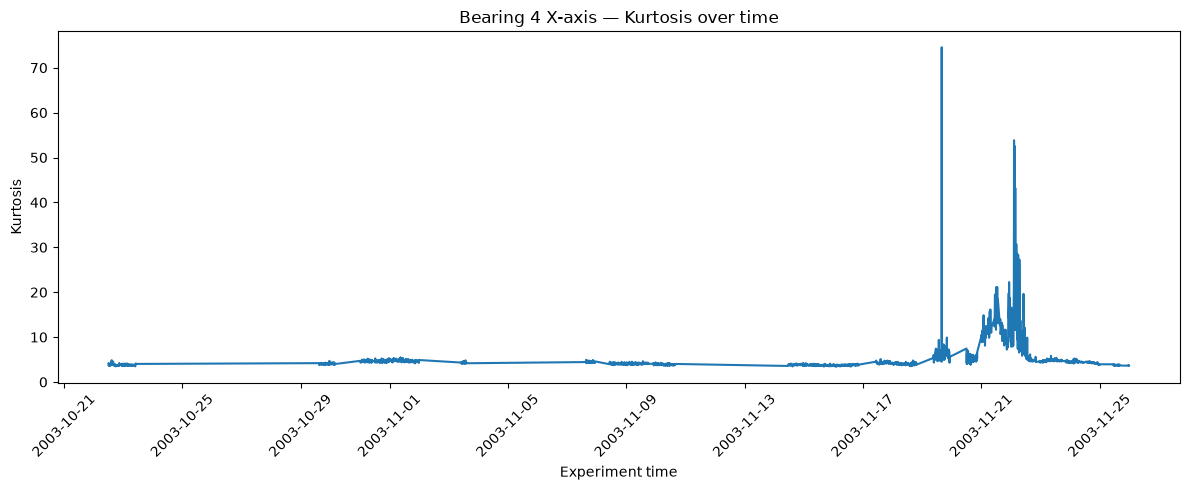

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["kurtosis"],
)

plt.xlabel("Experiment time")
plt.ylabel("Kurtosis")
plt.title("Bearing 4 X-axis — Kurtosis over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
feature_columns = [
    "rms",
    "std",
    "peak",
    "crest_factor",
    "kurtosis",
]

correlation_matrix = features_df[feature_columns].corr()

correlation_matrix

,rms,std,peak,crest_factor,kurtosis
rms,1.000000,0.962075,0.716179,0.564714,0.405552
std,0.962075,1.000000,0.738759,0.603498,0.419878
peak,0.716179,0.738759,1.000000,0.973375,0.832505
crest_factor,0.564714,0.603498,0.973375,1.000000,0.858087
kurtosis,0.405552,0.419878,0.832505,0.858087,1.000000


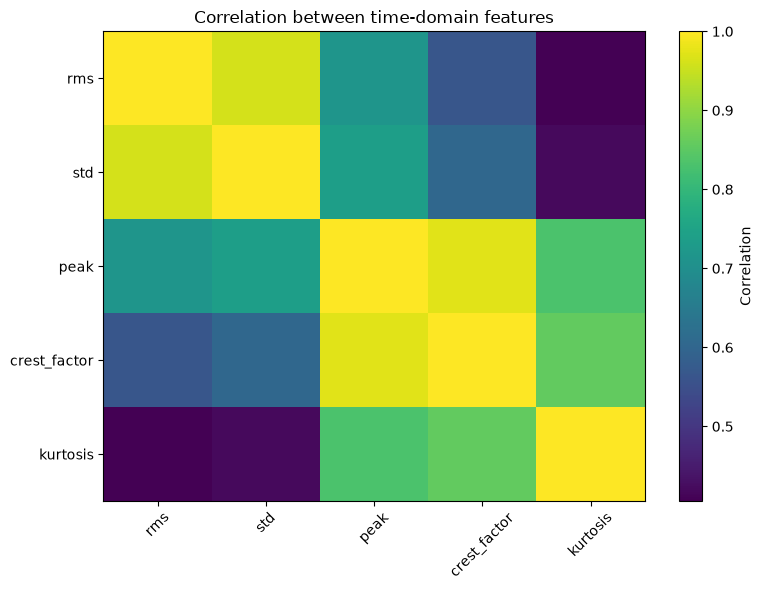

In [11]:
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    aspect="auto",
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(feature_columns)),
    feature_columns,
    rotation=45,
)

plt.yticks(
    range(len(feature_columns)),
    feature_columns,
)

plt.title("Correlation between time-domain features")
plt.tight_layout()
plt.show()

## Conclusions

The time-domain features show a clear change in the vibration behavior of Bearing 4 as the experiment approaches failure.

- **RMS** remains relatively stable during most of the experiment and increases substantially near the end, indicating a higher overall vibration magnitude.
- **Standard deviation** shows a similar but cleaner increasing trend, indicating that the vibration signal becomes increasingly variable.
- **Peak amplitude** becomes much larger and more unstable near the end of the experiment, suggesting the presence of stronger individual vibration impacts.
- **Crest factor** increases sharply during the degradation phase, indicating that some vibration peaks become unusually large relative to the overall vibration level.
- **Kurtosis** shows very large spikes during the degradation period, suggesting increasingly impulsive and heavy-tailed vibration behavior.

The correlation analysis also shows that some features contain overlapping information. RMS and standard deviation are strongly correlated, while peak amplitude, crest factor, and kurtosis are strongly related to each other.

Overall, the features appear to capture two complementary aspects of bearing condition:

1. **Overall vibration intensity**, mainly represented by RMS and standard deviation.
2. **Impulsive or shock-like behavior**, mainly represented by peak amplitude, crest factor, and kurtosis.

All five features will be retained for the initial machine-learning experiments. Feature selection can be evaluated later based on model performance and interpretability.

# Frequency-Domain Analysis

The time-domain features describe the overall magnitude, variability, and impulsiveness of the vibration signal.

This section analyzes the same vibration data in the frequency domain using the Fast Fourier Transform (FFT), with the goal of identifying dominant frequencies and extracting spectral features.

In [12]:
import pandas as pd
import numpy as np

from machineguard.features.frequency_domain import compute_fft

In [13]:
raw_file = Path(
    "../data/raw/IMS/1st_test/2003.10.22.12.06.24"
)

snapshot = pd.read_csv(
    raw_file,
    sep="\t",
    header=None,
)

signal = snapshot.iloc[:, 6]

In [14]:
sampling_rate = 20_000

frequencies, amplitudes = compute_fft(
    signal,
    sampling_rate,
)

In [15]:
frequencies.shape

(10241,)

In [16]:
amplitudes.shape

(10241,)

In [17]:
frequencies[0]

np.float64(0.0)

In [18]:
frequencies[-1]

np.float64(10000.0)

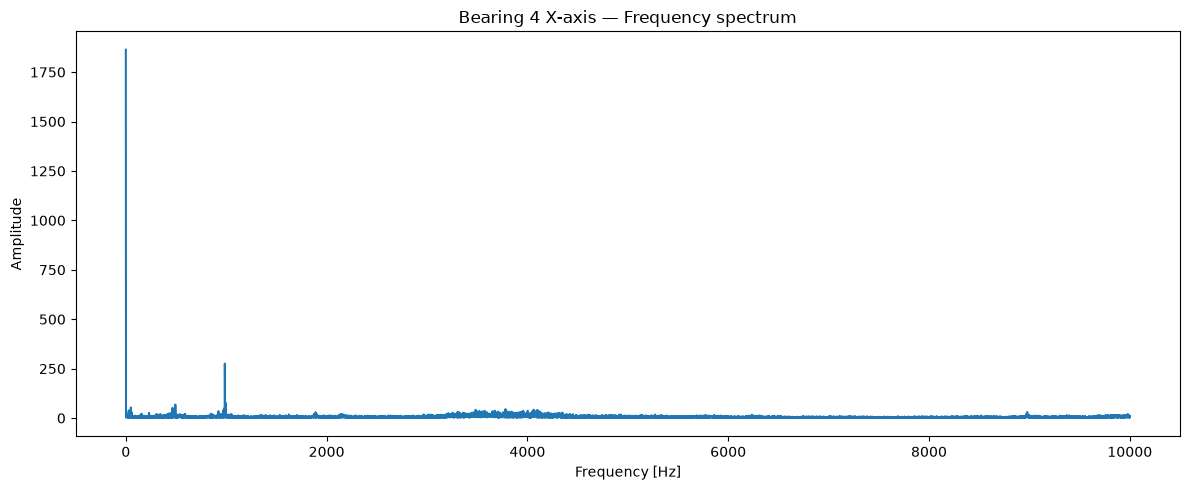

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    amplitudes,
)

plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("Bearing 4 X-axis — Frequency spectrum")

plt.tight_layout()
plt.show()

### Initial frequency spectrum

The FFT transforms the vibration signal from the time domain into the frequency domain.

In this spectrum, the large peak at 0 Hz corresponds to the DC component of the signal. This component is caused by the non-zero mean of the vibration measurements rather than by an oscillatory vibration frequency.

Since the goal is to analyze the vibration content of the bearing, the mean is removed from the signal before recomputing the spectrum. This reduces the DC component and makes the relevant vibration frequencies easier to inspect.

In [23]:
signal_centered = signal - np.mean(signal)

In [25]:
frequencies_centered, amplitudes_centered = compute_fft(
    signal_centered,
    sampling_rate,
)

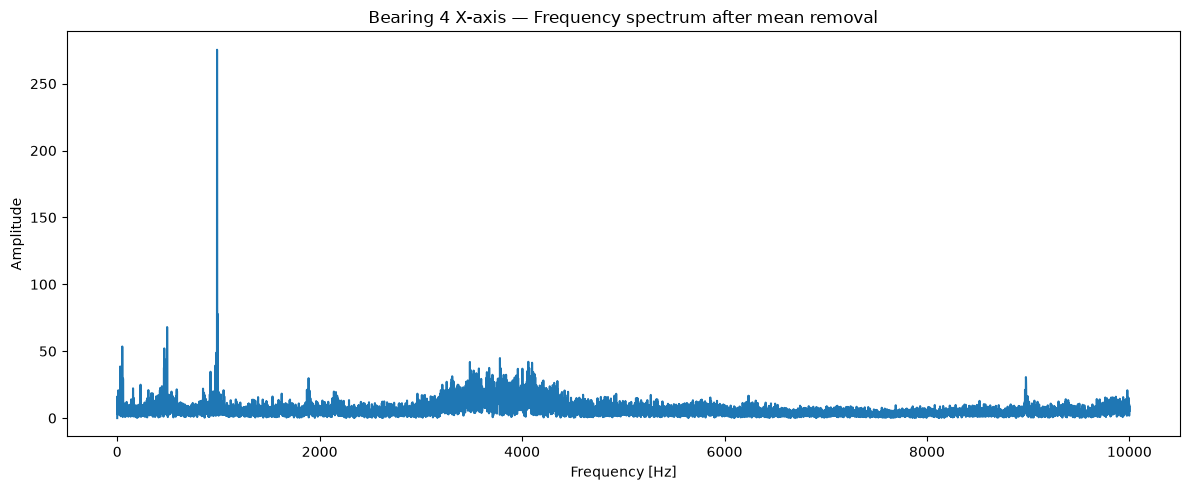

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    frequencies_centered,
    amplitudes_centered,
)

plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("Bearing 4 X-axis — Frequency spectrum after mean removal")

plt.tight_layout()
plt.show()

# Baseline Machine Learning

The first machine-learning task is binary condition classification:

- **0 — NORMAL**
- **1 — DEGRADED**

The NASA IMS dataset does not provide a health label for every snapshot. Therefore, the initial labels are derived heuristically from the run-to-failure timeline.

A tentative degradation boundary of November 20, 2003 is evaluated before creating the final target.

In [49]:
degradation_start = pd.Timestamp("2003-11-20")

normal_count = (
    features_df["timestamp"] < degradation_start
).sum()

degraded_count = (
    features_df["timestamp"] >= degradation_start
).sum()

normal_count, degraded_count

(np.int64(1507), np.int64(649))

In [50]:
features_df["target"] = (
    features_df["timestamp"] >= degradation_start
).astype(int)

In [51]:
features_df[["timestamp", "target"]].head()

,timestamp,target
0,2003-10-22 12:06:24,0
1,2003-10-22 12:09:13,0
2,2003-10-22 12:14:13,0
3,2003-10-22 12:19:13,0
4,2003-10-22 12:24:13,0


In [52]:
features_df[["timestamp", "target"]].tail()

,timestamp,target
2151,2003-11-25 16:07:32,1
2152,2003-11-25 23:13:21,1
2153,2003-11-25 23:19:56,1
2154,2003-11-25 23:29:56,1
2155,2003-11-25 23:39:56,1


In [53]:
ml_features = [
    "rms",
    "std",
    "peak",
    "crest_factor",
    "kurtosis",
    "dominant_frequency",
    "spectral_energy",
]

X = features_df[ml_features]
y = features_df["target"]

In [54]:
X.shape, y.shape

((2156, 7), (2156,))

In [55]:
healthy_train_end = pd.Timestamp("2003-11-15")

healthy_mask = features_df["timestamp"] < healthy_train_end

X_healthy = X[healthy_mask]

In [56]:
X_healthy.shape

(969, 7)

## Feature standardization

The seven input features have very different numerical scales. For example, RMS values are around 0.1, crest factor values are typically in the range of a few units, while dominant frequency is measured in hundreds or thousands of hertz and spectral energy can be much larger.

If these features are used directly, variables with larger numerical values can have a disproportionate influence on some machine-learning algorithms.

To make the features comparable, they are standardized using the training data:

$$
z = \frac{x - \mu}{\sigma}
$$

where:

- $x$ is the original feature value,
- $\mu$ is the mean of the feature in the healthy training set,
- $\sigma$ is the standard deviation of the feature in the healthy training set.

After standardization, each feature is expressed relative to the normal healthy baseline.

The scaler is fitted only on the healthy training subset and then applied to the full dataset. This avoids using information from the later degraded period during preprocessing and therefore reduces time leakage.

In [57]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_healthy_scaled = scaler.fit_transform(X_healthy)
X_scaled = scaler.transform(X)

In [58]:
X_healthy_scaled.shape, X_scaled.shape

((969, 7), (2156, 7))

In [59]:
X_healthy_scaled.mean(axis=0)

array([-1.11457684e-15,  3.04308808e-15,  7.33274237e-17, -7.03943268e-16,
       -7.62605207e-16, -8.21267146e-15,  6.67279556e-16])

In [60]:
X_healthy_scaled.std(axis=0)

array([1., 1., 1., 1., 1., 1., 1.])

## Isolation Forest anomaly detection

The first baseline model is an Isolation Forest trained only on the early healthy portion of the experiment.

The model does not learn explicit failure labels. Instead, it learns the multivariate feature patterns associated with normal bearing behavior.

After training, the model is applied to the full run-to-failure sequence. Snapshots whose feature combinations differ substantially from the healthy baseline receive more anomalous scores.

This allows MachineGuard to detect departures from normal operation without requiring ground-truth degradation labels for every snapshot.

In [66]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
)

isolation_forest.fit(X_healthy_scaled)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [67]:
decision_scores = isolation_forest.decision_function(X_scaled)

In [68]:
decision_scores.shape

(2156,)

In [69]:
pd.Series(decision_scores).describe()

count    2156.000000
mean       -0.037101
std         0.138117
min        -0.261779
25%        -0.198499
50%         0.006712
75%         0.089813
max         0.141682
dtype: float64

In [70]:
(decision_scores < 0).sum()

np.int64(1047)

### Distribution of Isolation Forest scores

The Isolation Forest assigns one decision score to each vibration snapshot.

Higher decision scores indicate observations that are more similar to the healthy training baseline, while lower scores indicate increasingly unusual feature combinations.

The distribution of these scores is inspected before analyzing how anomaly behavior evolves over time.

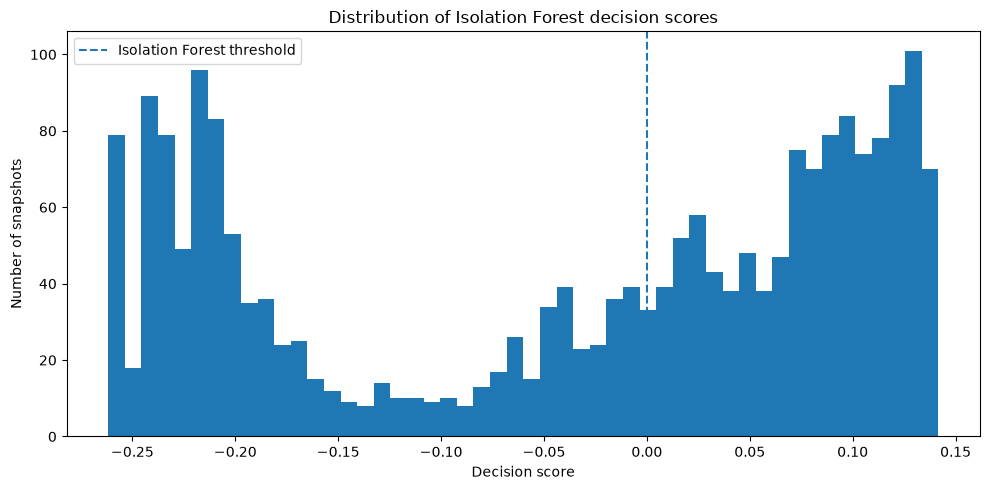

In [71]:
plt.figure(figsize=(10, 5))

plt.hist(
    decision_scores,
    bins=50,
)

plt.axvline(
    0,
    linestyle="--",
    label="Isolation Forest threshold",
)

plt.xlabel("Decision score")
plt.ylabel("Number of snapshots")
plt.title("Distribution of Isolation Forest decision scores")
plt.legend()

plt.tight_layout()
plt.show()

## Anomaly score over the run-to-failure timeline

The Isolation Forest decision score is now analyzed over time.

Higher decision scores indicate snapshots that are more similar to the healthy training baseline, while lower scores indicate increasingly anomalous feature combinations.

Plotting the score chronologically allows us to evaluate whether anomalous behavior becomes more frequent or more severe as the experiment approaches bearing failure.

In [72]:
features_df["decision_score"] = decision_scores

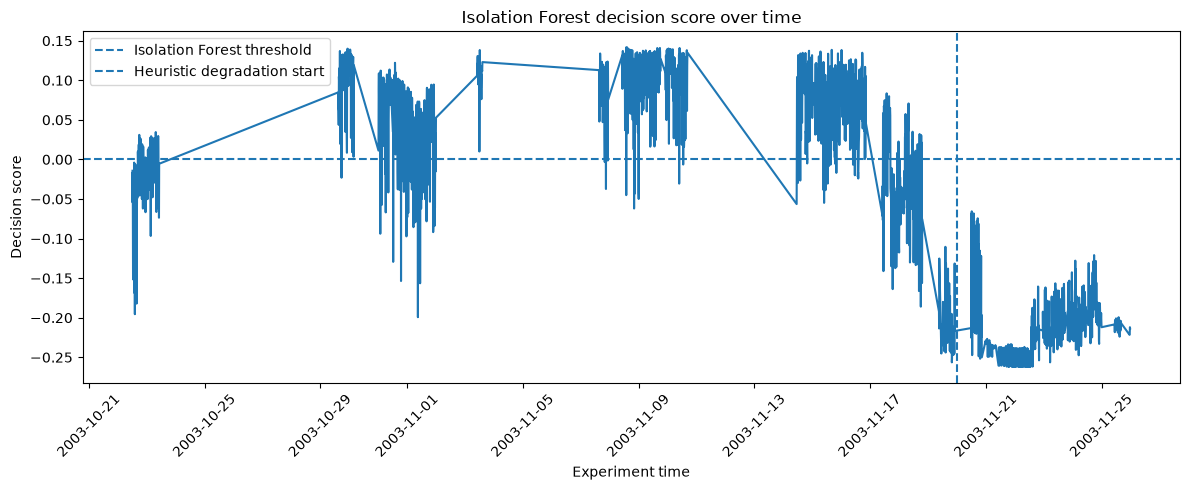

In [73]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["decision_score"],
)

plt.axhline(
    0,
    linestyle="--",
    label="Isolation Forest threshold",
)

plt.axvline(
    degradation_start,
    linestyle="--",
    label="Heuristic degradation start",
)

plt.xlabel("Experiment time")
plt.ylabel("Decision score")
plt.title("Isolation Forest decision score over time")
plt.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Healthy-baseline anomaly threshold

The default Isolation Forest decision boundary is determined by the model and is not specifically calibrated to the MachineGuard healthy baseline.

To obtain a more interpretable threshold, the distribution of decision scores within the healthy training period is examined.

A threshold can then be defined using a low percentile of the healthy scores. For example, using the 5th percentile means that approximately 5% of the healthy training snapshots would fall below the threshold and be treated as unusual.

This provides an explicit and interpretable false-alarm tolerance for the healthy baseline.

In [74]:
healthy_train_scores = isolation_forest.decision_function(
    X_healthy_scaled
)

In [75]:
(healthy_train_scores < 0).sum()

np.int64(178)

In [76]:
(healthy_train_scores < 0).mean()

np.float64(0.18369453044375644)

In [77]:
healthy_threshold = np.percentile(
    healthy_train_scores,
    5,
)

healthy_threshold

np.float64(-0.06108184766069839)

## Custom anomaly classification

The Isolation Forest produces a continuous decision score for each vibration snapshot.

To convert this score into an interpretable anomaly indicator, the custom threshold derived from the healthy training distribution is applied.

A snapshot is classified as anomalous when its decision score falls below the 5th-percentile healthy threshold.

Therefore:

- **0 — NORMAL-LIKE:** decision score is above or equal to the healthy threshold.
- **1 — ANOMALOUS:** decision score is below the healthy threshold.

This threshold allows approximately 5% of the healthy training snapshots to be flagged as unusual, providing an explicit false-alarm tolerance.

In [78]:
features_df["anomaly"] = (
    features_df["decision_score"] < healthy_threshold
).astype(int)

In [79]:
features_df["anomaly"].value_counts()

anomaly
0    1330
1     826
Name: count, dtype: int64

In [80]:
features_df["anomaly"].value_counts(normalize=True)

anomaly
0    0.616883
1    0.383117
Name: proportion, dtype: float64